<a href="https://colab.research.google.com/github/irafilina1990-sudo/Tarefa_Database/blob/main/%D0%9F%D0%97_1_%D0%BA%D0%B5%D0%B9%D1%81_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import random

# Генерация синтетического датасета вакансий
random.seed(42)
vacancies = []
hard_skills_pool = ['SQL', 'Python', 'Pandas', 'Power BI', 'Tableau', 'Excel', 'Yandex DataLens', 'Apache Spark', 'R', 'Git']
soft_skills_pool = ['Презентации', 'Работа в команде', 'Критическое мышление', 'Внимание к деталям', 'Английский язык']
roles = ['Data Analyst', 'BI Analyst', 'Product Analyst', 'Marketing Analyst']

for i in range(50):
    # Случайно выбираем 3-5 хард-скиллов и 1-2 софт-скилла
    h_skills = random.sample(hard_skills_pool, random.randint(3, 5))
    s_skills = random.sample(soft_skills_pool, random.randint(1, 2))
    vacancies.append({
        'id': i+1,
        'role': random.choice(roles),
        'company': f'Company_{random.randint(1, 20)}',
        'requirements': ', '.join(h_skills + s_skills)
    })

# Намеренно добавляем дубликат и пропуск для демонстрации очистки
vacancies.append(vacancies[0])
vacancies[2]['requirements'] = None

df = pd.DataFrame(vacancies)

# --- ЗАДАНИЕ ДЛЯ СТУДЕНТА ---
# 1. Удалите дубликаты и строки с пропусками (None/NaN).
# 2. Подсчитайте частоту упоминания каждого навыка в колонке 'requirements'.
# 3. Выведите Топ-5 самых популярных навыков.



In [3]:
# Шаг 1: Удаление полных дубликатов
df_clean = df.drop_duplicates()
print(f"После удаления дубликатов: {len(df_clean)} строк (удалено: {len(df) - len(df_clean)})")

# Шаг 2: Удаление строк с пропусками в ключевом поле 'requirements'
df_clean = df_clean.dropna(subset=['requirements'])
print(f"После удаления пропусков: {len(df_clean)} строк (удалено: {len(df) - len(df_clean) - (len(df) - len(df.drop_duplicates()))})")

# Шаг 3: Валидация — проверка, что все оставшиеся записи корректны
print(f"\nФинальный размер датасета: {len(df_clean)} вакансий")
print(f"Уникальных компаний: {df_clean['company'].nunique()}")
print(f"Распределение ролей:\n{df_clean['role'].value_counts()}")

После удаления дубликатов: 50 строк (удалено: 1)
После удаления пропусков: 49 строк (удалено: 1)

Финальный размер датасета: 49 вакансий
Уникальных компаний: 18
Распределение ролей:
role
Marketing Analyst    14
Data Analyst         12
BI Analyst           12
Product Analyst      11
Name: count, dtype: int64


In [4]:
# Разделяем hard и soft skills для независимого анализа
hard_skills_pool = ['SQL', 'Python', 'Pandas', 'Power BI', 'Tableau', 'Excel', 'Yandex DataLens', 'Apache Spark', 'R', 'Git']
soft_skills_pool = ['Презентации', 'Работа в команде', 'Критическое мышление', 'Внимание к деталям', 'Английский язык']

# Функция подсчета вхождений навыка в колонку requirements
def count_skill_occurrences(df, skill, column='requirements'):
    """Считает, в скольких вакансиях встречается навык (регистронезависимо)."""
    return df[column].fillna('').str.lower().str.contains(skill.lower(), regex=False).sum()

# Подсчет для всех навыков
hard_skills_counts = {skill: count_skill_occurrences(df_clean, skill) for skill in hard_skills_pool}
soft_skills_counts = {skill: count_skill_occurrences(df_clean, skill) for skill in soft_skills_pool}

# Перевод в DataFrame для удобства
df_hard = pd.DataFrame(list(hard_skills_counts.items()), columns=['Skill', 'Count']).sort_values('Count', ascending=False)
df_soft = pd.DataFrame(list(soft_skills_counts.items()), columns=['Skill', 'Count']).sort_values('Count', ascending=False)

# Добавляем процент от общего числа вакансий
total_vacancies = len(df_clean)
df_hard['Percentage'] = (df_hard['Count'] / total_vacancies * 100).round(1)
df_soft['Percentage'] = (df_soft['Count'] / total_vacancies * 100).round(1)

print("=== Hard Skills (частота упоминаний) ===")
print(df_hard.to_string(index=False))
print(f"\n=== Soft Skills (частота упоминаний) ===")
print(df_soft.to_string(index=False))

=== Hard Skills (частота упоминаний) ===
          Skill  Count  Percentage
              R     39        79.6
            SQL     25        51.0
        Tableau     25        51.0
         Python     23        46.9
          Excel     21        42.9
       Power BI     20        40.8
Yandex DataLens     18        36.7
         Pandas     15        30.6
   Apache Spark     14        28.6
            Git     13        26.5

=== Soft Skills (частота упоминаний) ===
               Skill  Count  Percentage
    Работа в команде     18        36.7
     Английский язык     18        36.7
  Внимание к деталям     15        30.6
Критическое мышление     13        26.5
         Презентации     12        24.5


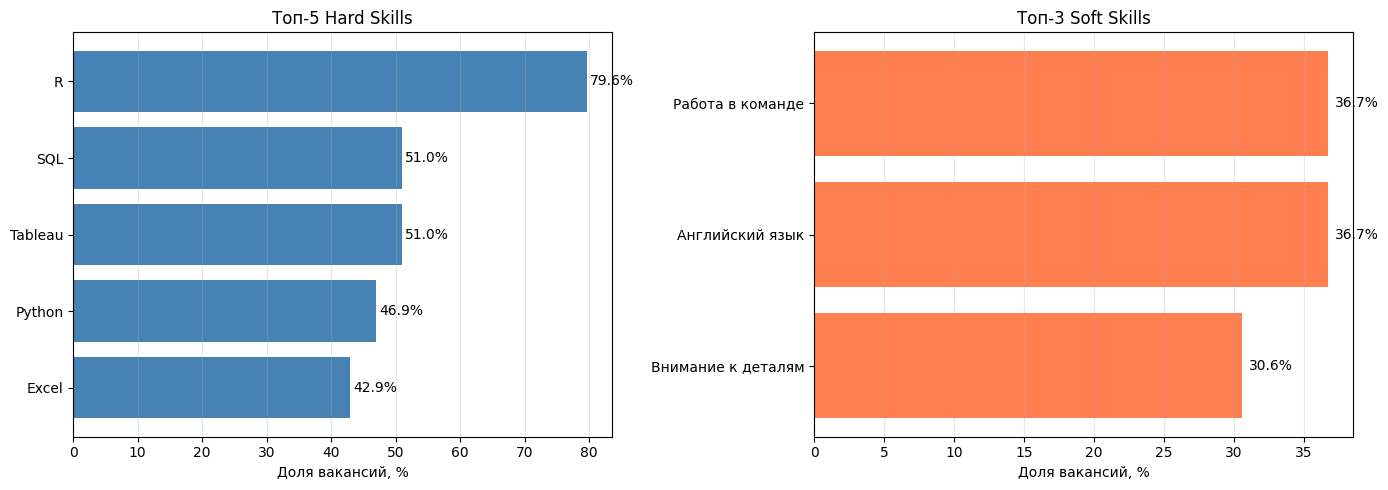

Топ-5 Hard Skills: ['R', 'SQL', 'Tableau', 'Python', 'Excel']
Их доля: [79.6, 51.0, 51.0, 46.9, 42.9]%

Топ-3 Soft Skills: ['Работа в команде', 'Английский язык', 'Внимание к деталям']
Их доля: [36.7, 36.7, 30.6]%


In [5]:
import matplotlib.pyplot as plt

# Настройка отображения кириллицы
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Топ-5 Hard Skills
top5_hard = df_hard.head(5)
axes[0].barh(top5_hard['Skill'][::-1], top5_hard['Percentage'][::-1], color='steelblue')
axes[0].set_xlabel('Доля вакансий, %')
axes[0].set_title('Топ-5 Hard Skills')
axes[0].grid(axis='x', alpha=0.3)
for i, v in enumerate(top5_hard['Percentage'][::-1]):
    axes[0].text(v + 0.5, i, f'{v:.1f}%', va='center')

# Топ-3 Soft Skills
top3_soft = df_soft.head(3)
axes[1].barh(top3_soft['Skill'][::-1], top3_soft['Percentage'][::-1], color='coral')
axes[1].set_xlabel('Доля вакансий, %')
axes[1].set_title('Топ-3 Soft Skills')
axes[1].grid(axis='x', alpha=0.3)
for i, v in enumerate(top3_soft['Percentage'][::-1]):
    axes[1].text(v + 0.5, i, f'{v:.1f}%', va='center')

plt.tight_layout()
plt.show()

# Вывод числовых результатов
print(f"Топ-5 Hard Skills: {list(top5_hard['Skill'])}")
print(f"Их доля: {list(top5_hard['Percentage'])}%")
print(f"\nТоп-3 Soft Skills: {list(top3_soft['Skill'])}")
print(f"Их доля: {list(top3_soft['Percentage'])}%")